In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import *


INFO       Cache size for target 'cython': 2395 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [2]:
start_scope()

SEED = 2
seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------
# Simulation
# ------------------------------------------------------------
DT = 0.02*ms                 # 20 us; 60 us DBS pulse = 3 time steps
REC_DT = 0.20*ms             # recording interval for LFP / selected cell
defaultclock.dt = DT

NE = 400
NI = 100

# Record one representative E neuron.
# Change this BEFORE running cell 3 if you want another neuron.
CHOSEN_E = 200

# ------------------------------------------------------------
# Hodgkin-Huxley membrane
# ------------------------------------------------------------
CM = 200*pF
G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

# ------------------------------------------------------------
# Synaptic kinetics
# Keep these fixed; tune conductances / drive rather than time constants
# to move the emergent network rhythm.
# ------------------------------------------------------------
E_AMPA = 0*mV
E_GABA = -80*mV

TAU_AMPA_RISE  = 0.5*ms
TAU_AMPA_DECAY = 2.0*ms

TAU_GABA_RISE  = 0.5*ms
TAU_GABA_DECAY = 8.0*ms

def biexp_norm(tau_rise, tau_decay):
    # Normalize exp(-t/tau_decay)-exp(-t/tau_rise) so its peak is 1.
    tr = float(tau_rise/ms)
    td = float(tau_decay/ms)

    t_peak = (tr*td/(td-tr))*np.log(td/tr)
    peak = np.exp(-t_peak/td) - np.exp(-t_peak/tr)

    return 1.0/peak

AMPA_NORM = biexp_norm(TAU_AMPA_RISE, TAU_AMPA_DECAY)
GABA_NORM = biexp_norm(TAU_GABA_RISE, TAU_GABA_DECAY)

print(f'AMPA normalization = {AMPA_NORM:.3f}')
print(f'GABA normalization = {GABA_NORM:.3f}')

# ------------------------------------------------------------
# Recurrent conductance strengths
# Because of the normalization above, these W values are approximately
# the PEAK conductance produced by one presynaptic event.
# ------------------------------------------------------------
W_EE = 1.5*nS
W_EI = 2.0*nS
W_IE = 3.0*nS
W_II = 3.0*nS

# Sparse random recurrent connectivity
P_EE = 0.10
P_EI = 0.20
P_IE = 0.10
P_II = 0.10

# ------------------------------------------------------------
# Background drive
# ------------------------------------------------------------
I_TONIC_E = 0.35*nA
I_TONIC_I = 0.30*nA

N_EXT_E = 400
N_EXT_I = 100

RATE_EXT_E = 8*Hz
RATE_EXT_I = 8*Hz

W_EXT_E = 1.6*nS
W_EXT_I = 1.5*nS

# ------------------------------------------------------------
# DBS: 55 Hz, 60 us, 0 -> 10 mA staircase
# ------------------------------------------------------------
DBS_FREQ = 55*Hz
DBS_PULSE_WIDTH = 60*us

AMP_LEVELS_MA = np.arange(0.0, 11.0, 1.0)  # 0,1,...,10 mA
AMP_DURATION = 1.0*second                  # >= 1 s at every amplitude

SIM_TIME = len(AMP_LEVELS_MA) * AMP_DURATION

# Phenomenological model conversion only.
# It is NOT a physical electrode-mA -> somatic-nA conversion.
DBS_GAIN_NA_PER_MA = 1.0*nA

# Preserve your current choice: DBS reaches both populations.
DBS_TARGET_E = 1.0
DBS_TARGET_I = 1.0

# Continuous 55-Hz pulse train; only amplitude changes every second.
dt_s = float(DT/second)
sim_s = float(SIM_TIME/second)
amp_duration_s = float(AMP_DURATION/second)
freq_hz = float(DBS_FREQ/Hz)
pw_s = float(DBS_PULSE_WIDTH/second)

n_steps = int(np.ceil(sim_s/dt_s))
dbs_t = np.arange(n_steps)*dt_s

amp_index = np.floor(dbs_t/amp_duration_s).astype(int)
amp_index = np.clip(amp_index, 0, len(AMP_LEVELS_MA)-1)
dbs_amp_trace_mA = AMP_LEVELS_MA[amp_index]

phase = np.mod(dbs_t, 1.0/freq_hz)
pulse_mask = phase < pw_s

dbs_waveform_nA = (
    dbs_amp_trace_mA
    * float(DBS_GAIN_NA_PER_MA/nA)
    * pulse_mask.astype(float)
)

dbs_ta = TimedArray(dbs_waveform_nA*nA, dt=DT)

print(f'Simulation duration = {float(SIM_TIME/second):.1f} s')
print(f'Amplitude levels = {AMP_LEVELS_MA}')
print(f'DBS pulse width / DT = {float(DBS_PULSE_WIDTH/DT):.1f} steps')

# ------------------------------------------------------------
# Hodgkin-Huxley + double-exponential synaptic equations
#
# AMPA spike: xA += W and yA += W
# GABA spike: xG += W and yG += W
# ------------------------------------------------------------
eqs = r"""
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + gA*(E_AMPA-v)
    + gG*(E_GABA-v)
    + I_tonic
    + I_dbs
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dxA/dt = -xA/TAU_AMPA_RISE : siemens
dyA/dt = -yA/TAU_AMPA_DECAY : siemens
gA = AMPA_NORM*(yA - xA) : siemens

dxG/dt = -xG/TAU_GABA_RISE : siemens
dyG/dt = -yG/TAU_GABA_DECAY : siemens
gG = GABA_NORM*(yG - xG) : siemens

I_tonic : amp
dbs_target : 1
I_dbs = dbs_target * dbs_ta(t) : amp
"""

namespace = {
    'CM': CM,
    'G_NA': G_NA,
    'G_K': G_K,
    'G_L': G_L,
    'E_NA': E_NA,
    'E_K': E_K,
    'E_L': E_L,
    'E_AMPA': E_AMPA,
    'E_GABA': E_GABA,
    'TAU_AMPA_RISE': TAU_AMPA_RISE,
    'TAU_AMPA_DECAY': TAU_AMPA_DECAY,
    'TAU_GABA_RISE': TAU_GABA_RISE,
    'TAU_GABA_DECAY': TAU_GABA_DECAY,
    'AMPA_NORM': AMPA_NORM,
    'GABA_NORM': GABA_NORM,
    'dbs_ta': dbs_ta,
}

# ------------------------------------------------------------
# Neurons
# ------------------------------------------------------------
E = NeuronGroup(
    NE,
    eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='E'
)

I = NeuronGroup(
    NI,
    eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='I'
)

for G in (E, I):
    G.v = -65*mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318

    # gA and gG are read-only subexpressions now.
    G.xA = 0*nS
    G.yA = 0*nS
    G.xG = 0*nS
    G.yG = 0*nS

E.I_tonic = np.clip(
    rng.normal(float(I_TONIC_E/nA), 0.05, NE),
    0.05, None
)*nA

I.I_tonic = np.clip(
    rng.normal(float(I_TONIC_I/nA), 0.04, NI),
    0.05, None
)*nA

E.dbs_target = DBS_TARGET_E
I.dbs_target = DBS_TARGET_I

# ------------------------------------------------------------
# Sparse random recurrent connectivity
#
# IMPORTANT:
#   E synapses increment BOTH xA and yA.
#   I synapses increment BOTH xG and yG.
# ------------------------------------------------------------

S_EE = Synapses(
    E, E,
    on_pre="""
        xA_post += W_EE
        yA_post += W_EE
    """,
    namespace={'W_EE': W_EE},
    name='S_EE'
)
S_EE.connect(condition='i != j', p=P_EE)
S_EE.delay = '1*ms + rand()*2*ms'

S_EI = Synapses(
    E, I,
    on_pre="""
        xA_post += W_EI
        yA_post += W_EI
    """,
    namespace={'W_EI': W_EI},
    name='S_EI'
)
S_EI.connect(p=P_EI)
S_EI.delay = '1*ms + rand()*2*ms'

S_IE = Synapses(
    I, E,
    on_pre="""
        xG_post += W_IE
        yG_post += W_IE
    """,
    namespace={'W_IE': W_IE},
    name='S_IE'
)
S_IE.connect(p=P_IE)
S_IE.delay = '2*ms + rand()*3*ms'

S_II = Synapses(
    I, I,
    on_pre="""
        xG_post += W_II
        yG_post += W_II
    """,
    namespace={'W_II': W_II},
    name='S_II'
)
S_II.connect(condition='i != j', p=P_II)
S_II.delay = '2*ms + rand()*3*ms'

# ------------------------------------------------------------
# Independent background AMPA
#
# A double-exponential conductance needs the SAME event to increment
# both xA and yA. Therefore use one aggregate PoissonGroup source
# per postsynaptic neuron and a one-to-one synapse.
# ------------------------------------------------------------
EXT_E = PoissonGroup(
    NE,
    rates=N_EXT_E*RATE_EXT_E,
    name='EXT_E'
)

EXT_I = PoissonGroup(
    NI,
    rates=N_EXT_I*RATE_EXT_I,
    name='EXT_I'
)

S_EXT_E = Synapses(
    EXT_E, E,
    on_pre="""
        xA_post += W_EXT_E
        yA_post += W_EXT_E
    """,
    namespace={'W_EXT_E': W_EXT_E},
    name='S_EXT_E'
)
S_EXT_E.connect(j='i')

S_EXT_I = Synapses(
    EXT_I, I,
    on_pre="""
        xA_post += W_EXT_I
        yA_post += W_EXT_I
    """,
    namespace={'W_EXT_I': W_EXT_I},
    name='S_EXT_I'
)
S_EXT_I.connect(j='i')

# ------------------------------------------------------------
# Monitors
# ------------------------------------------------------------
M_E = StateMonitor(
    E,
    ['v', 'gA', 'gG'],
    record=[CHOSEN_E],
    dt=REC_DT,
    name='M_E'
)

SP_E = SpikeMonitor(E, name='SP_E')
SP_I = SpikeMonitor(I, name='SP_I')

RATE_E = PopulationRateMonitor(E, name='RATE_E')
RATE_I = PopulationRateMonitor(I, name='RATE_I')

# Record population LFP proxy online so we do NOT need to store
# gA/gG/v for all 400 E neurons for the full 11-s simulation.
lfp_time_s = []
lfp_total_trace = []
lfp_AMPA_trace = []
lfp_GABA_trace = []

@network_operation(dt=REC_DT, when='end')
def record_lfp():
    I_AMPA = E.gA * (E_AMPA - E.v)
    I_GABA = E.gG * (E_GABA - E.v)

    # Signed population-average synaptic current proxy.
    lfp_AMPA = -np.mean(I_AMPA/nA)
    lfp_GABA = -np.mean(I_GABA/nA)

    lfp_time_s.append(float(defaultclock.t/second))
    lfp_AMPA_trace.append(float(lfp_AMPA))
    lfp_GABA_trace.append(float(lfp_GABA))
    lfp_total_trace.append(float(lfp_AMPA + lfp_GABA))

net = Network(
    E, I,
    S_EE, S_EI, S_IE, S_II,
    EXT_E, EXT_I, S_EXT_E, S_EXT_I,
    M_E, SP_E, SP_I, RATE_E, RATE_I,
    record_lfp
)

# ============================================================
# Analysis helpers
# ============================================================

def get_lfp():
    return (
        np.asarray(lfp_time_s),
        np.asarray(lfp_total_trace),
        np.asarray(lfp_AMPA_trace),
        np.asarray(lfp_GABA_trace)
    )


def selected_neuron_input_proxy():
    I_AMPA = np.asarray(
        (M_E.gA[0] * (E_AMPA - M_E.v[0]))/nA
    )

    I_GABA = np.asarray(
        (M_E.gG[0] * (E_GABA - M_E.v[0]))/nA
    )

    return -(I_AMPA + I_GABA)


def amplitude_window(amp_mA):
    idx = int(np.where(AMP_LEVELS_MA == amp_mA)[0][0])

    start = idx*float(AMP_DURATION/second)
    stop = start + float(AMP_DURATION/second)

    return start, stop


def rates_by_amplitude():
    tE = np.asarray(SP_E.t/second)
    tI = np.asarray(SP_I.t/second)

    rows = []

    for amp in AMP_LEVELS_MA:
        start, stop = amplitude_window(amp)
        duration = stop-start

        e_rate = np.sum((tE >= start) & (tE < stop))/(NE*duration)
        i_rate = np.sum((tI >= start) & (tI < stop))/(NI*duration)

        rows.append((amp, e_rate, i_rate))

    return np.asarray(rows)


def print_basic_rates():
    rates = rates_by_amplitude()

    print('amp_mA    E_rate_Hz    I_rate_Hz')
    for amp, er, ir in rates:
        print(f'{amp:5.1f}      {er:7.2f}      {ir:7.2f}')


def plot_dbs_summary(fmax=140):
    t_cell = np.asarray(M_E.t/second)

    lfp_t, lfp, lfp_AMPA, lfp_GABA = get_lfp()
    single_input = selected_neuron_input_proxy()

    fs = 1.0/float(REC_DT/second)
    block_s = float(AMP_DURATION/second)

    # 1) Chosen HH neuron + its input + population LFP
    fig, ax = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

    ax[0].plot(t_cell, np.asarray(M_E.v[0]/mV), lw=0.5)
    ax[0].set_ylabel('V_E (mV)')
    ax[0].set_title(f'Chosen E neuron {CHOSEN_E}')

    ax[1].plot(t_cell, single_input, lw=0.55)
    ax[1].set_ylabel('Synaptic input\n(nA, proxy)')

    ax[2].plot(lfp_t, lfp, lw=0.6)
    ax[2].set_ylabel('Population\nLFP proxy')
    ax[2].set_xlabel('Time (s)')

    for j in range(1, len(AMP_LEVELS_MA)):
        x = j*block_s
        for a in ax:
            a.axvline(x, lw=0.5, alpha=0.35)

    plt.tight_layout()
    plt.show()

    # 2) AMPA / GABA components of the population proxy
    fig, ax = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

    ax[0].plot(lfp_t, lfp_AMPA, lw=0.6)
    ax[0].set_ylabel('AMPA proxy')

    ax[1].plot(lfp_t, lfp_GABA, lw=0.6)
    ax[1].set_ylabel('GABA proxy')

    ax[2].plot(lfp_t, lfp, lw=0.6)
    ax[2].set_ylabel('Total proxy')
    ax[2].set_xlabel('Time (s)')

    for j in range(1, len(AMP_LEVELS_MA)):
        x = j*block_s
        for a in ax:
            a.axvline(x, lw=0.5, alpha=0.35)

    plt.tight_layout()
    plt.show()

    # 3) E raster
    plt.figure(figsize=(14, 4))
    plt.plot(
        np.asarray(SP_E.t/second),
        np.asarray(SP_E.i),
        '.',
        markersize=1.0
    )

    for j in range(1, len(AMP_LEVELS_MA)):
        plt.axvline(j*block_s, lw=0.5, alpha=0.35)

    plt.xlabel('Time (s)')
    plt.ylabel('E neuron index')
    plt.title('Excitatory spike raster')
    plt.tight_layout()
    plt.show()

    # 4) E/I population firing rate
    plt.figure(figsize=(14, 4))

    plt.plot(
        RATE_E.t/second,
        RATE_E.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='E population rate'
    )

    plt.plot(
        RATE_I.t/second,
        RATE_I.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='I population rate'
    )

    for j in range(1, len(AMP_LEVELS_MA)):
        plt.axvline(j*block_s, lw=0.5, alpha=0.35)

    plt.xlabel('Time (s)')
    plt.ylabel('Population rate (Hz)')
    plt.title('Smoothed population firing rates')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 5) Mean firing rate versus DBS amplitude
    rates = rates_by_amplitude()

    plt.figure(figsize=(8, 4))
    plt.plot(rates[:, 0], rates[:, 1], 'o-', label='E')
    plt.plot(rates[:, 0], rates[:, 2], 'o-', label='I')
    plt.xlabel('DBS amplitude label (mA)')
    plt.ylabel('Mean firing rate (Hz / neuron)')
    plt.title('Firing rate versus DBS amplitude')
    plt.xticks(AMP_LEVELS_MA)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 6) PSD at selected amplitudes
    selected_amps = [0, 2, 5, 8, 10]

    plt.figure(figsize=(11, 5))

    for amp in selected_amps:
        start, stop = amplitude_window(amp)

        use = (
            (lfp_t >= start + 0.10)
            & (lfp_t < stop)
        )

        x = signal.detrend(lfp[use])

        f, pxx = signal.welch(
            x,
            fs=fs,
            nperseg=len(x)
        )

        keep = (f >= 5) & (f <= fmax)
        plt.semilogy(f[keep], pxx[keep], label=f'{amp} mA')

    plt.axvspan(13, 30, alpha=0.08, label='beta')
    plt.axvline(27.5, ls='--', lw=1, label='f/2 = 27.5')
    plt.axvline(55.0, ls='--', lw=1, label='f = 55')
    plt.axvline(82.5, ls='--', lw=1, label='3f/2 = 82.5')
    plt.axvline(110.0, ls='--', lw=1, label='2f = 110')

    plt.xlabel('Frequency (Hz)')
    plt.ylabel('PSD')
    plt.title('Population LFP proxy — PSD by DBS amplitude')
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

    # 7) Spectrogram across 0 -> 10 mA
    nper = int(0.50*fs)
    nover = int(0.45*fs)

    f_s, tt, Sxx = signal.spectrogram(
        signal.detrend(lfp),
        fs=fs,
        nperseg=nper,
        noverlap=nover,
        scaling='density',
        mode='psd'
    )

    keep = (f_s >= 5) & (f_s <= fmax)

    plt.figure(figsize=(15, 6))
    plt.pcolormesh(
        tt,
        f_s[keep],
        10*np.log10(Sxx[keep] + 1e-18),
        shading='auto'
    )

    for j in range(1, len(AMP_LEVELS_MA)):
        plt.axvline(j*block_s, lw=0.6, alpha=0.45)

    for j, amp in enumerate(AMP_LEVELS_MA):
        plt.text(
            (j + 0.5)*block_s,
            fmax - 3,
            f'{amp:g} mA',
            ha='center',
            va='top',
            fontsize=8
        )

    plt.axhline(27.5, ls='--', lw=1)
    plt.axhline(55.0, ls='--', lw=1)
    plt.axhline(82.5, ls='--', lw=1)
    plt.axhline(110.0, ls='--', lw=1)

    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Population LFP proxy — 55 Hz DBS, amplitude 0 -> 10 mA')
    plt.colorbar(label='Power (dB, arbitrary)')
    plt.tight_layout()
    plt.show()

    # 8) Verify actual 60 us stimulation waveform at 5 mA
    start_5, _ = amplitude_window(5)
    zoom = (dbs_t >= start_5) & (dbs_t <= start_5 + 0.040)

    plt.figure(figsize=(10, 3))
    plt.step(
        1000*(dbs_t[zoom] - start_5),
        dbs_waveform_nA[zoom],
        where='post'
    )
    plt.xlabel('Time from start of 5 mA block (ms)')
    plt.ylabel('Effective model current (nA)')
    plt.title('55 Hz DBS waveform — 60 us pulses, 5 mA block')
    plt.tight_layout()
    plt.show()

    return lfp


AMPA normalization = 2.117
GABA normalization = 1.283
Simulation duration = 11.0 s
Amplitude levels = [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
DBS pulse width / DT = 3.0 steps


In [3]:
net.run(SIM_TIME, report='text')

print_basic_rates()


Starting simulation at t=0. s for a duration of 11. s
0.40502 s (3%) simulated in 10s, estimated 4m 22s remaining.
0.74734 s (6%) simulated in 20s, estimated 4m 36s remaining.
1.14542 s (10%) simulated in 30s, estimated 4m 19s remaining.
1.5648 s (14%) simulated in 40s, estimated 4m 2s remaining.
1.96602 s (17%) simulated in 50s, estimated 3m 50s remaining.
2.30242 s (20%) simulated in 1m 0s, estimated 3m 47s remaining.
2.71802 s (24%) simulated in 1m 10s, estimated 3m 34s remaining.
3.11042 s (28%) simulated in 1m 20s, estimated 3m 23s remaining.
3.44702 s (31%) simulated in 1m 30s, estimated 3m 17s remaining.
3.85742 s (35%) simulated in 1m 40s, estimated 3m 5s remaining.
4.26902 s (38%) simulated in 1m 50s, estimated 2m 54s remaining.
4.65402 s (42%) simulated in 2m 1s, estimated 2m 45s remaining.
5.05722 s (45%) simulated in 2m 11s, estimated 2m 34s remaining.
5.47056 s (49%) simulated in 2m 21s, estimated 2m 23s remaining.
5.87824 s (53%) simulated in 2m 31s, estimated 2m 12s rema

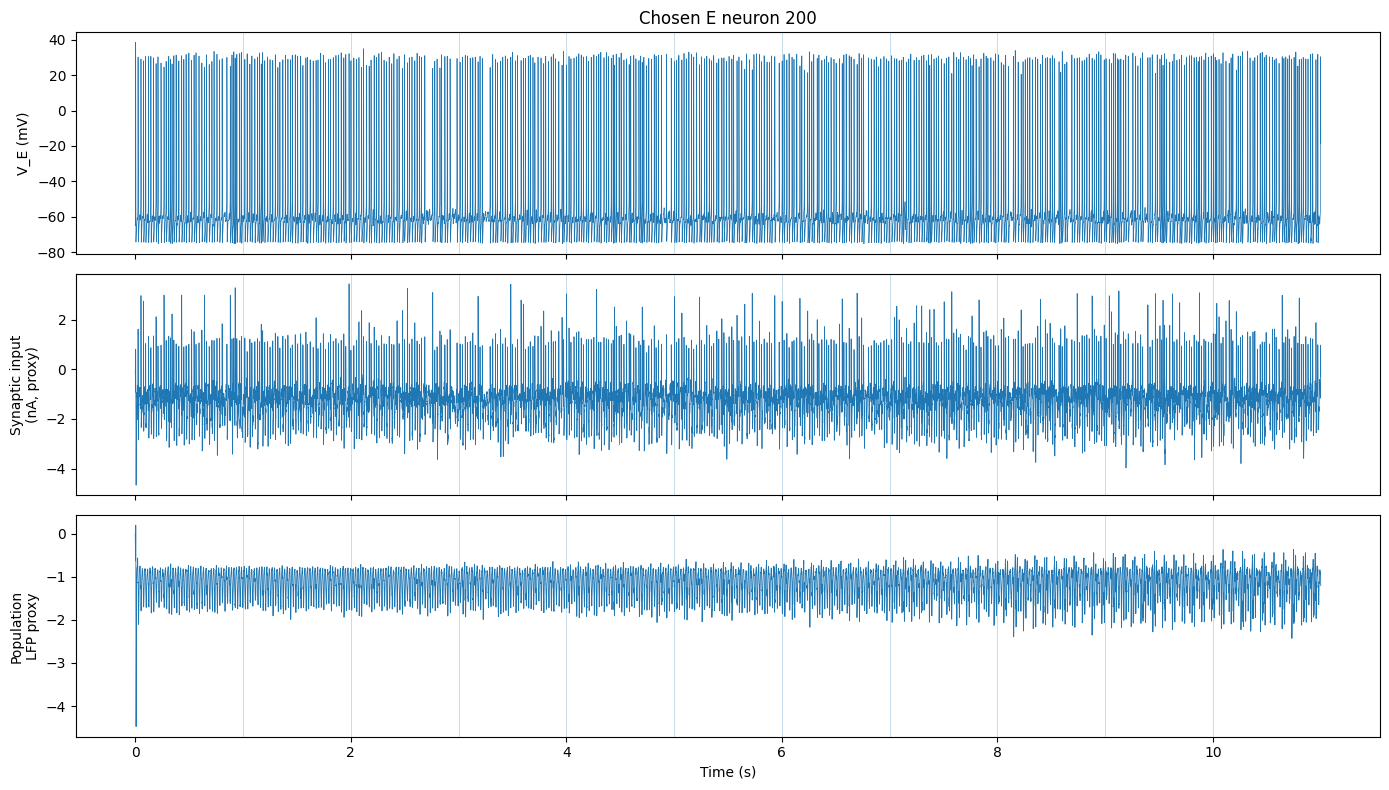

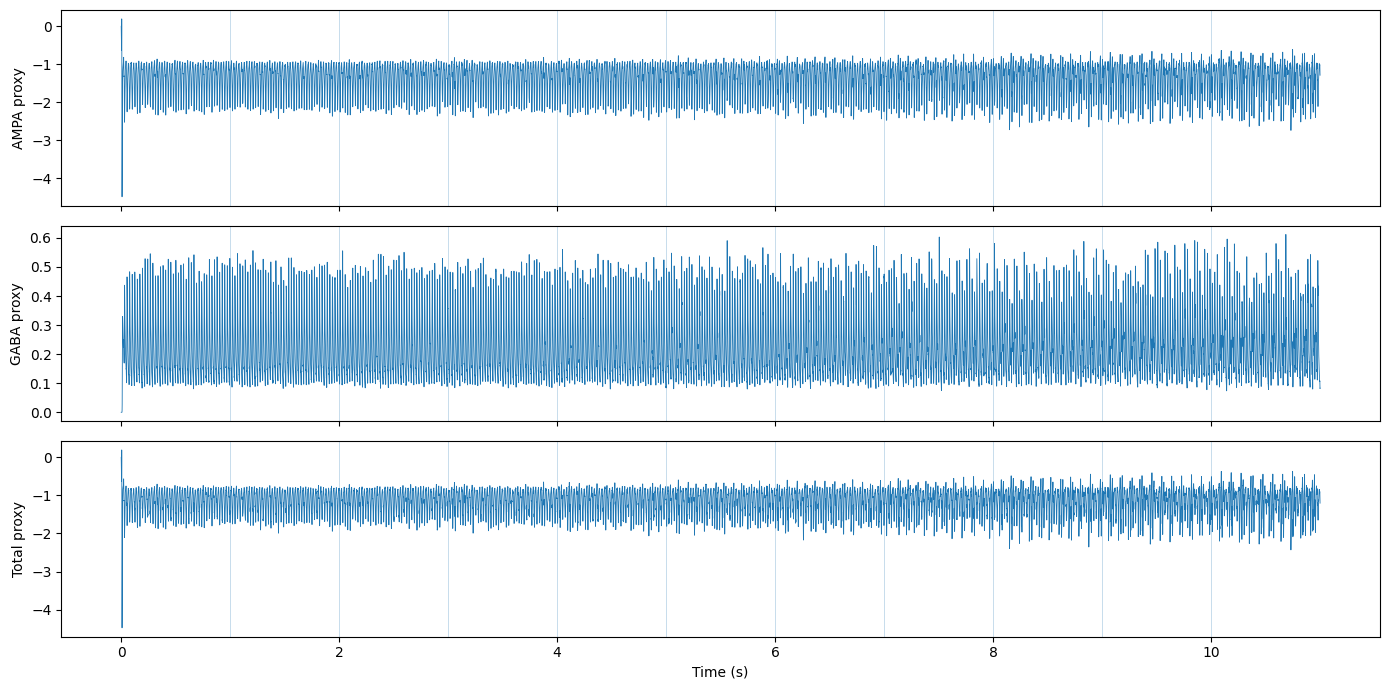

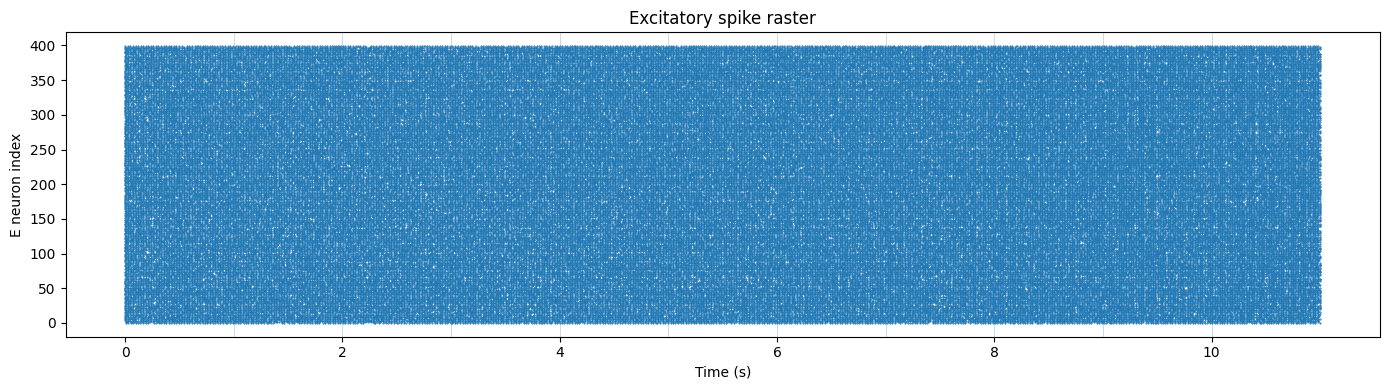

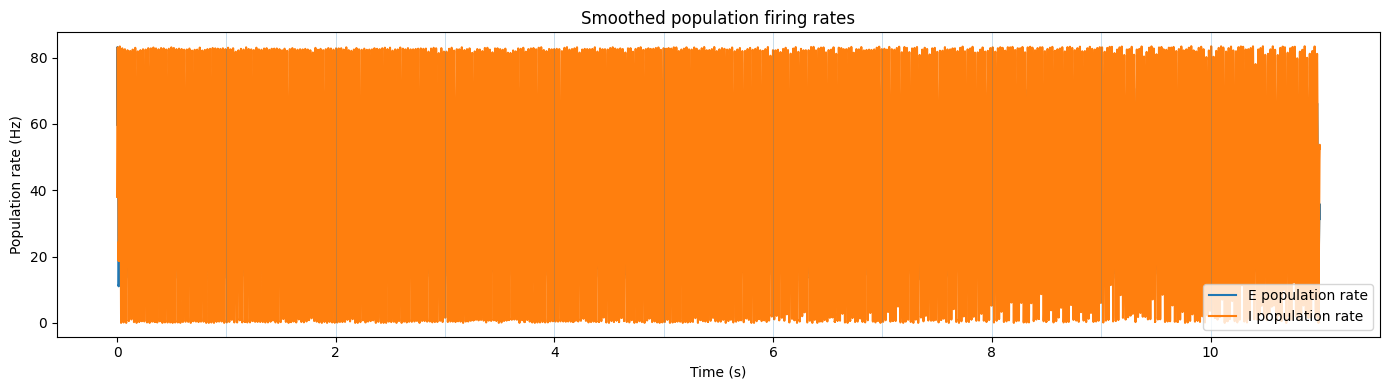

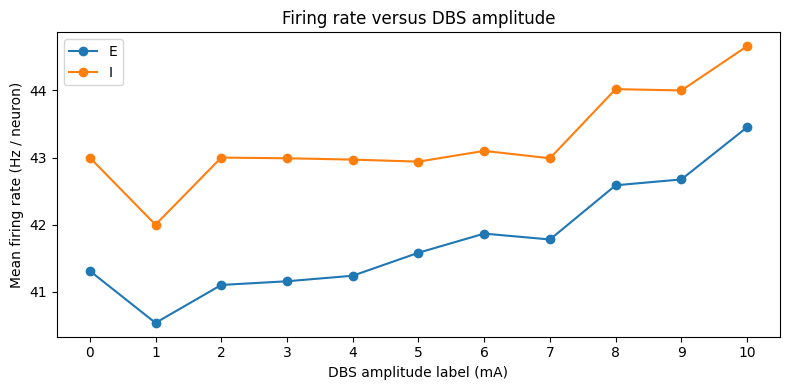

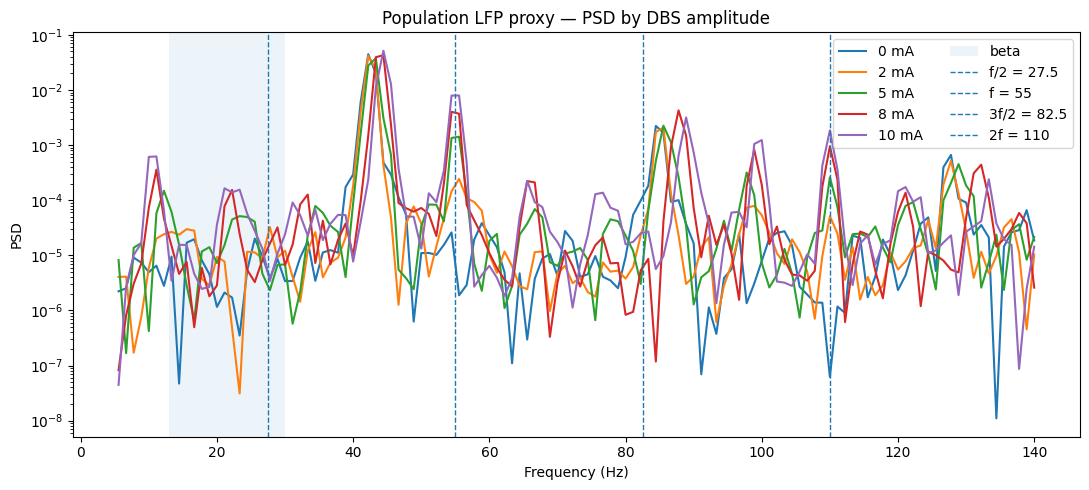

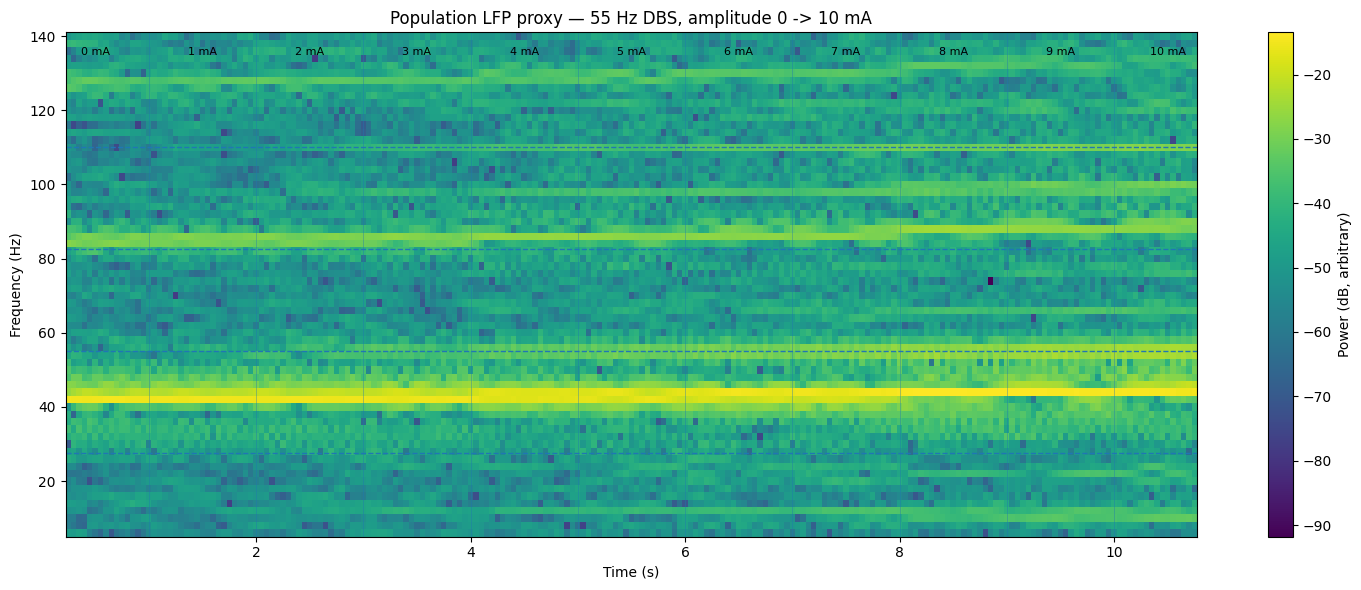

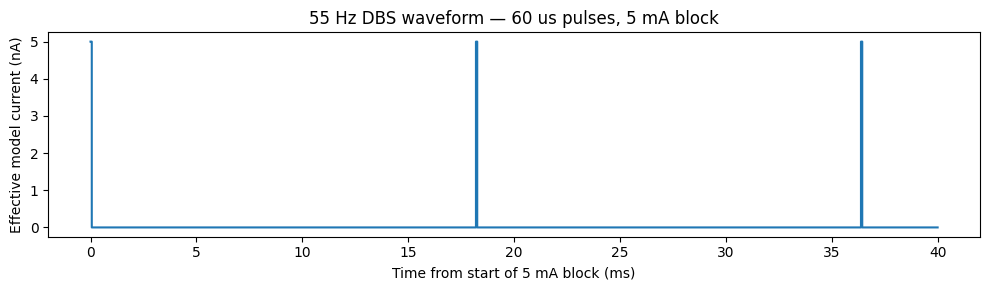

In [4]:
lfp = plot_dbs_summary(fmax=140)
